In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [18]:
# read in weighted data
pi_df = pd.read_csv('../data/new_pi_data_weight3.csv')
# pair with longhurst data
final_rates_geo = pd.read_csv('../data/final_rates_geo.csv')
# merge with pi data
pi_merged = pi_df.merge(final_rates_geo[['cruise', 'cruise_day', 'pop', 'biome', 'region']])
# plot distributions by biome
pi_30min = pi_merged.loc[pi_merged['time_res'] == '30min'].reset_index(drop = True)
pi_1H = pi_merged.loc[pi_merged['time_res'] == '1H'].reset_index(drop = True)

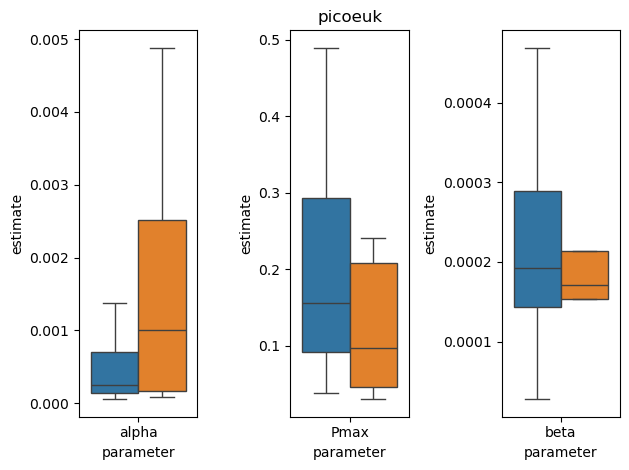

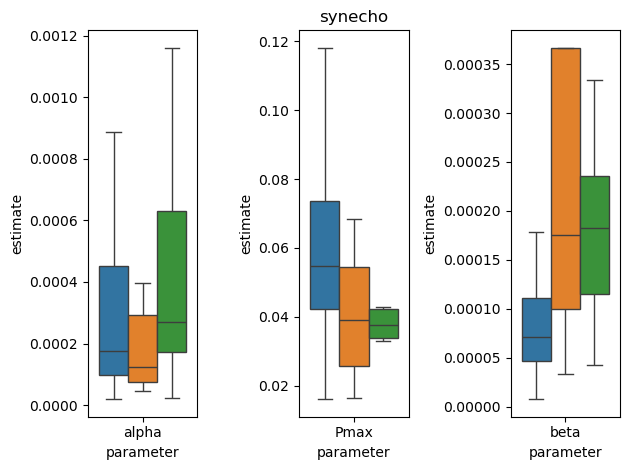

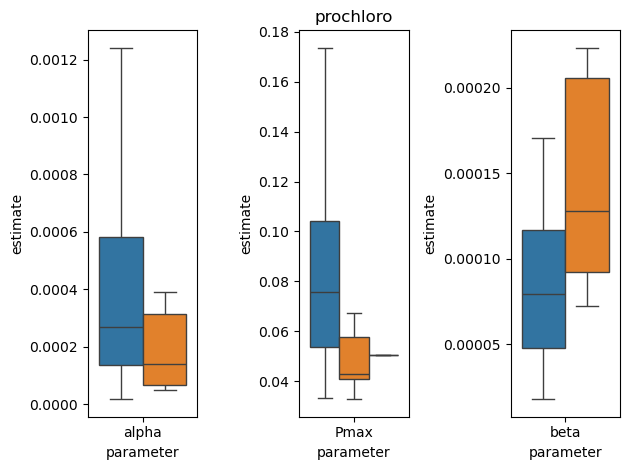

In [3]:
import matplotlib.pyplot as plt
# loop through each population
for pop in pi_30min['pop'].unique():
    pop_df = pi_30min.loc[pi_30min['pop'] == pop]
    fig, axs = plt.subplots(ncols = 3)
    ax_count = 0
    # plot with seaborn- loop through each parameter
    for param in pi_30min['parameter'].unique():
        param_df = pop_df.loc[pop_df['parameter'] == param]
        sns.boxplot(param_df, x = 'parameter', y = 'estimate', hue = 'biome', 
                    showfliers = False, ax= axs[ax_count], legend = False)
        # axs.set_title(pop)
        ax_count +=1
    axs[ax_count-2].set_title(pop)
    plt.tight_layout()

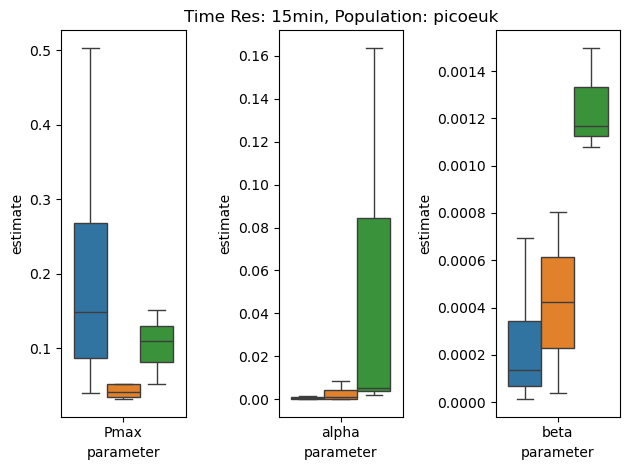

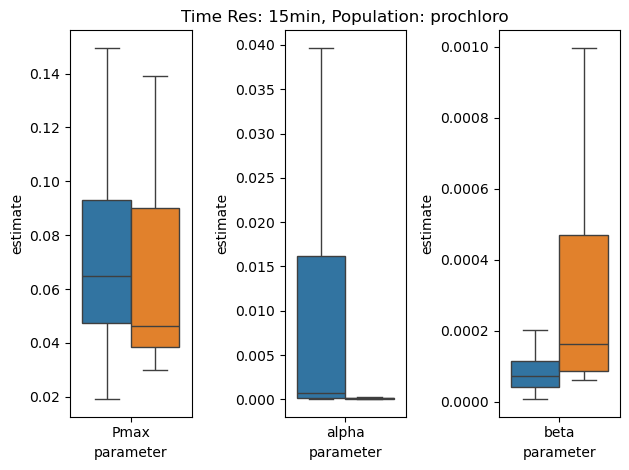

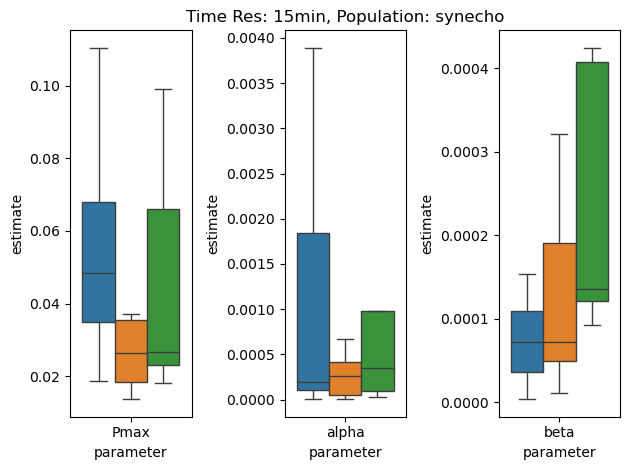

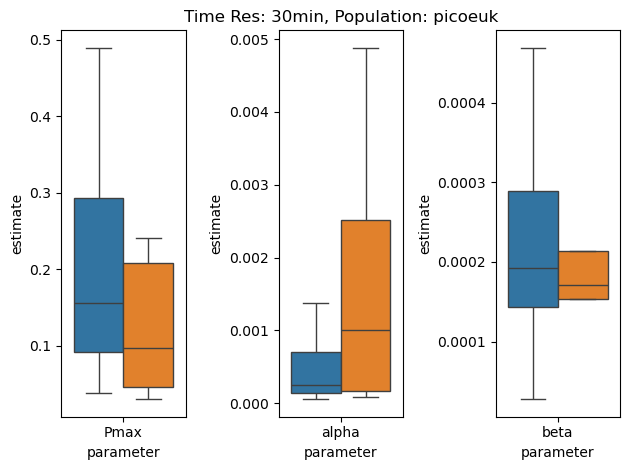

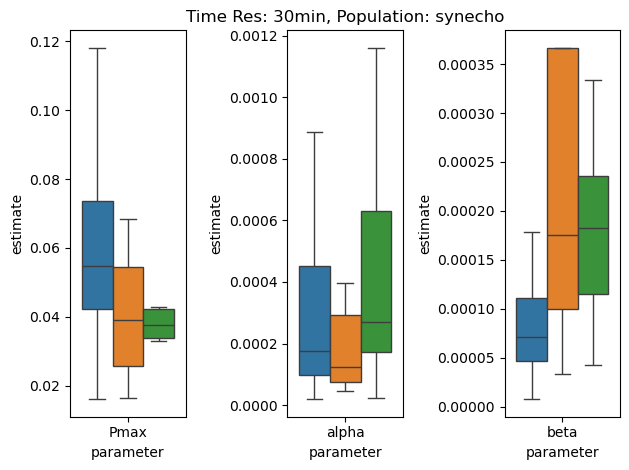

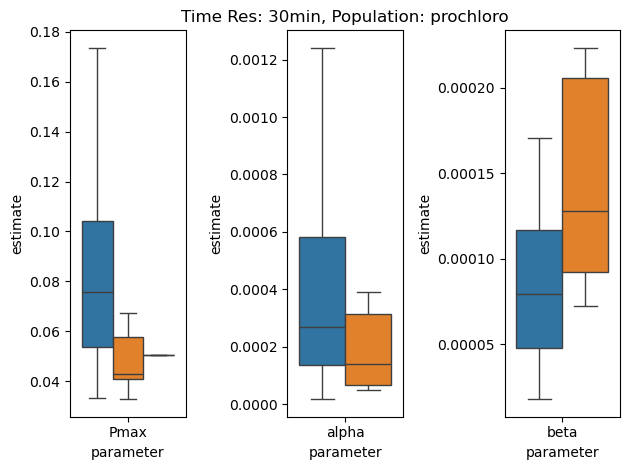

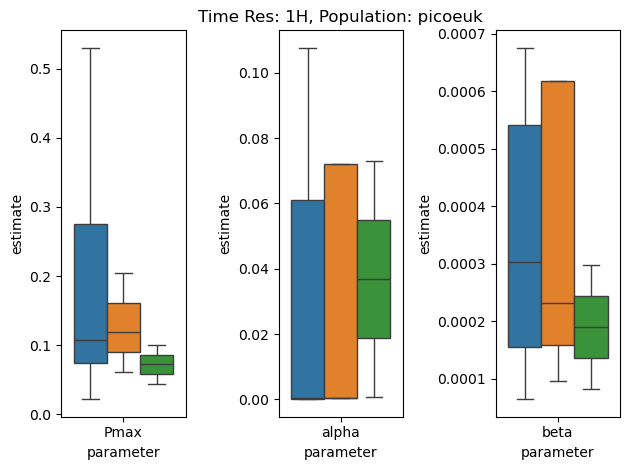

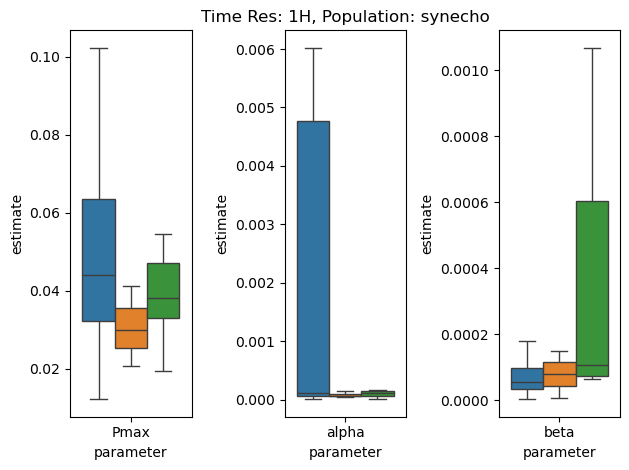

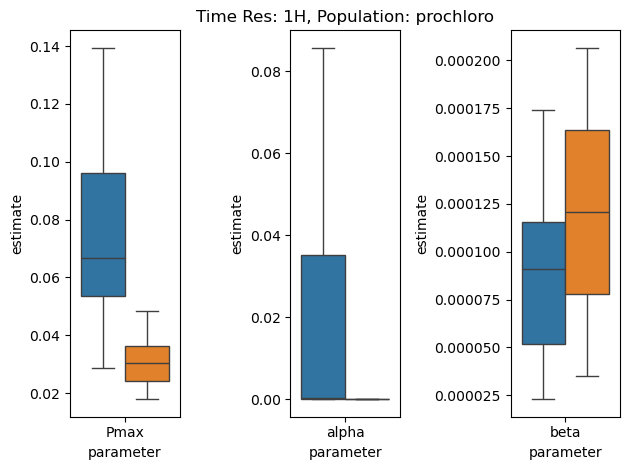

In [4]:
import matplotlib.pyplot as plt
# loop through each time resolution and see how distributions change 
for timeres in pi_merged['time_res'].unique():
    time_df = pi_merged.loc[pi_merged['time_res'] == timeres]
    # loop through each population
    for pop in time_df['pop'].unique():
        pop_df = time_df.loc[time_df['pop'] == pop]
        fig, axs = plt.subplots(ncols = 3)
        ax_count = 0
        # plot with seaborn- loop through each parameter
        for param in pi_merged['parameter'].unique():
            param_df = pop_df.loc[pop_df['parameter'] == param]
            sns.boxplot(param_df, x = 'parameter', y = 'estimate', hue = 'biome', 
                        showfliers = False, ax= axs[ax_count], legend = False)
            # axs.set_title(pop)
            ax_count +=1
        axs[ax_count-2].set_title(f'Time Res: {timeres}, Population: {pop}')
        plt.tight_layout()

In [19]:
## generate PI curve based on these distributions for each population and time resolution
# read in pi label data
all_pi_labs = pd.read_csv('../data/all_pi_labels.csv')
# subset to just the cols we need 
all_pi_sub = all_pi_labs[['cruise', 'cruise_day', 'pop', 'index_id', 'time_res', 'hour', 'P', 'I']]

# merge with parameter data for different time resolutions
pi_30min_all = pi_30min.merge(all_pi_sub)
pi_1H_all = pi_1H.merge(all_pi_sub)


### Check if growth rate data makes sense

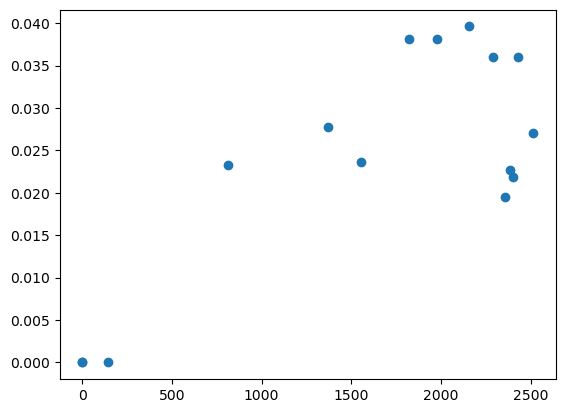

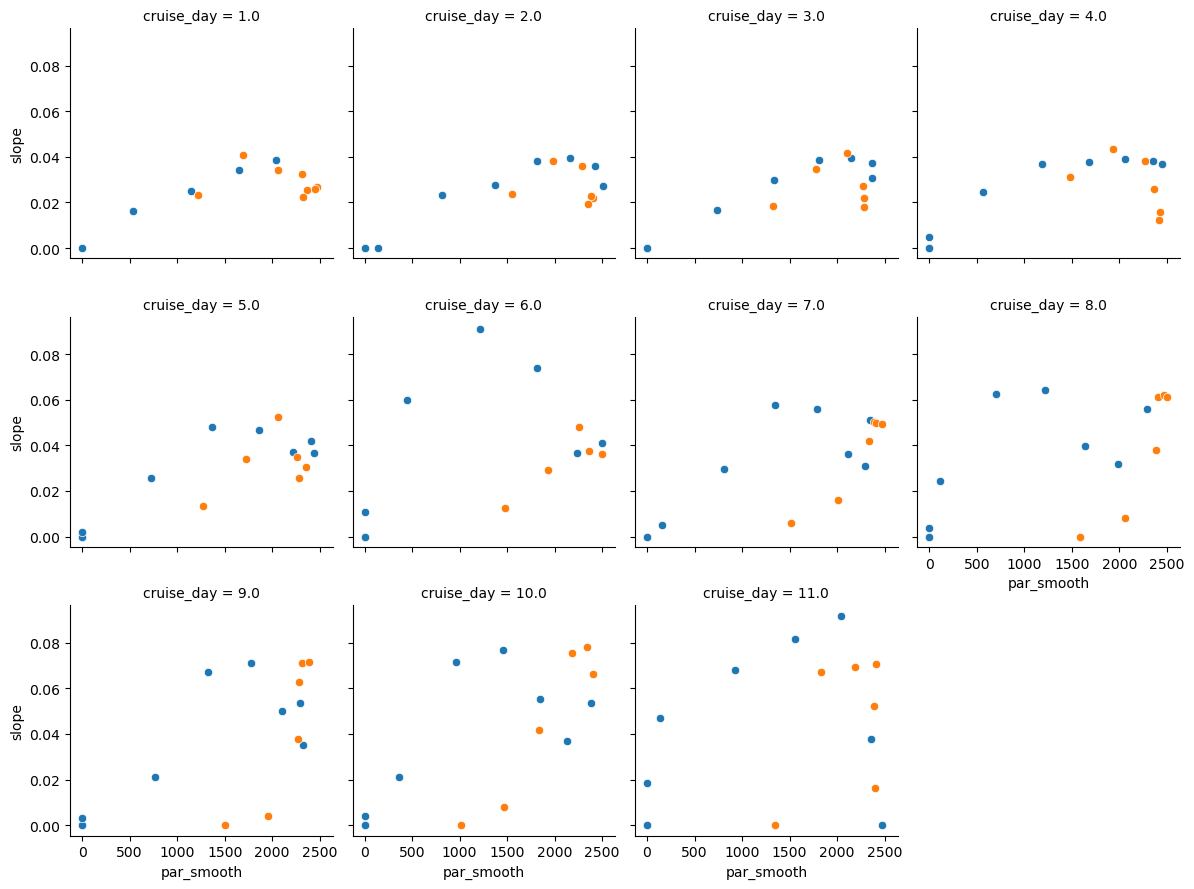

In [50]:
growth_1H = pd.read_csv('../data/clean_growth_1H.csv')
diel_test = growth_1H.loc[(growth_1H['cruise'] == 'KM1513') & 
                          (growth_1H['pop'] == 'prochloro')]

day2_test = diel_test.loc[diel_test['cruise_day'] == 2]
plt.scatter(day2_test['par_smooth'], day2_test['slope'])
# make facetplot
g = sns.FacetGrid(diel_test, col = 'cruise_day', hue = 'day_half', col_wrap = 4)
g.map(sns.scatterplot, 'par_smooth', 'slope')

In [48]:
diel_test.loc[diel_test['cruise_day'] == 2]

,Unnamed: 0,cruise_day,pop,time,hour,slope,yint,mld,par_smooth,int_par,round_par,cruise,season,halfway_hour,day_half
878,13,2.0,prochloro,2015-07-26 09:00:00,0.0,0.000000,0.000000,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
879,14,2.0,prochloro,2015-07-26 10:00:00,1.0,0.000000,0.038798,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
880,15,2.0,prochloro,2015-07-26 15:00:00,2.0,0.000000,-0.056436,31.666667,143.650977,5.171435e+05,150.0,KM1513,Summer,9.0,first
881,16,2.0,prochloro,2015-07-26 16:00:00,3.0,0.023245,-0.246103,31.666667,811.827317,3.439722e+06,800.0,KM1513,Summer,9.0,first
882,17,2.0,prochloro,2015-07-26 17:00:00,4.0,0.027708,-0.263957,31.666667,1370.117155,8.372144e+06,1350.0,KM1513,Summer,9.0,first
883,18,2.0,prochloro,2015-07-26 18:00:00,5.0,0.038108,-0.315957,31.666667,1818.520490,1.491882e+07,1800.0,KM1513,Summer,9.0,first
884,19,2.0,prochloro,2015-07-26 19:00:00,6.0,0.039605,-0.324936,31.666667,2157.037322,2.268415e+07,2150.0,KM1513,Summer,9.0,first
885,20,2.0,prochloro,2015-07-26 20:00:00,7.0,0.035969,-0.299484,31.666667,2425.861573,3.141725e+07,2450.0,KM1513,Summer,9.0,first
886,21,2.0,prochloro,2015-07-26 21:00:00,8.0,0.027003,-0.227760,31.666667,2512.161436,4.046103e+07,2500.0,KM1513,Summer,9.0,first
887,22,2.0,prochloro,2015-07-26 22:00:00,9.0,0.021804,-0.180968,31.666667,2399.089206,4.909776e+07,2400.0,KM1513,Summer,9.0,second


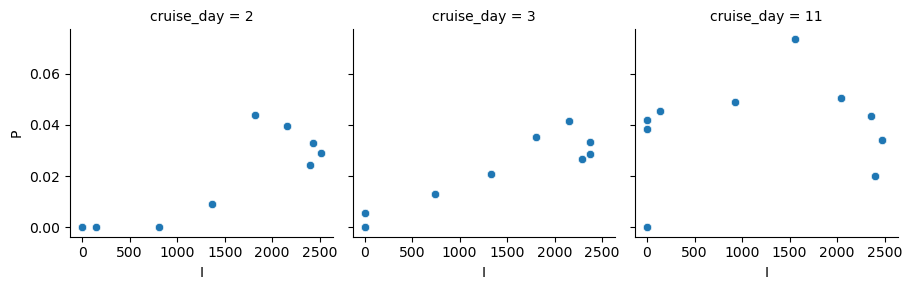

In [39]:
diel_pi_test = pi_1H_all.loc[(pi_1H_all['cruise'] == 'KM1513') & 
                          (pi_1H_all['pop'] == 'prochloro')]

# make facetplot
g = sns.FacetGrid(diel_pi_test, col = 'cruise_day', col_wrap = 4)
g.map(sns.scatterplot, 'I', 'P')

In [47]:
day2_test

,Unnamed: 0,cruise_day,pop,time,hour,slope,yint,mld,par_smooth,int_par,round_par,cruise,season,halfway_hour,day_half
878,13,2.0,prochloro,2015-07-26 09:00:00,0.0,0.000000,0.000000,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
879,14,2.0,prochloro,2015-07-26 10:00:00,1.0,0.000000,0.038798,31.666667,0.000000,0.000000e+00,0.0,KM1513,Summer,9.0,first
880,15,2.0,prochloro,2015-07-26 15:00:00,2.0,0.000000,-0.056436,31.666667,143.650977,5.171435e+05,150.0,KM1513,Summer,9.0,first
881,16,2.0,prochloro,2015-07-26 16:00:00,3.0,0.023245,-0.246103,31.666667,811.827317,3.439722e+06,800.0,KM1513,Summer,9.0,first
882,17,2.0,prochloro,2015-07-26 17:00:00,4.0,0.027708,-0.263957,31.666667,1370.117155,8.372144e+06,1350.0,KM1513,Summer,9.0,first
883,18,2.0,prochloro,2015-07-26 18:00:00,5.0,0.038108,-0.315957,31.666667,1818.520490,1.491882e+07,1800.0,KM1513,Summer,9.0,first
884,19,2.0,prochloro,2015-07-26 19:00:00,6.0,0.039605,-0.324936,31.666667,2157.037322,2.268415e+07,2150.0,KM1513,Summer,9.0,first
885,20,2.0,prochloro,2015-07-26 20:00:00,7.0,0.035969,-0.299484,31.666667,2425.861573,3.141725e+07,2450.0,KM1513,Summer,9.0,first
886,21,2.0,prochloro,2015-07-26 21:00:00,8.0,0.027003,-0.227760,31.666667,2512.161436,4.046103e+07,2500.0,KM1513,Summer,9.0,first
887,22,2.0,prochloro,2015-07-26 22:00:00,9.0,0.021804,-0.180968,31.666667,2399.089206,4.909776e+07,2400.0,KM1513,Summer,9.0,second


In [46]:
diel_pi_test.loc[diel_pi_test['cruise_day']==2]

,time_res,index_id,cruise,cruise_day,pop,n_obs,parameter,estimate,log_estimate,biome,region,hour,P,I
3601,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,0.0,0.000000,0.000000
3602,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,1.0,0.000000,0.000000
3603,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,2.0,0.000000,143.650977
3604,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,3.0,0.000000,811.827317
3605,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,4.0,0.009087,1370.117155
3606,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,5.0,0.043852,1818.520490
3607,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,6.0,0.039594,2157.037322
3608,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,7.0,0.032752,2425.861573
3609,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,8.0,0.028921,2512.161436
3610,1H,pi-86,KM1513,2,prochloro,10,alpha,0.000016,-11.054417,Trades,NPTG,9.0,0.024239,2399.089206
